# 01 · Read RFMiD 1.0 and RFMiD 2.0

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from PIL import Image

# Works whether VS Code starts the kernel in paper-1/ or in paper-1/notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import config, data

config.ensure_output_dirs()
pd.set_option("display.max_columns", 60, "display.width", 200)
print("Project root:", config.PROJECT_ROOT)
print("Data root   :", config.DATA_ROOT)

Project root: C:\Users\Sajjad\Documents\Documents\paper-1\paper-1
Data root   : C:\Users\Sajjad\Documents\Documents\paper-3\datasets


## 2. Check the configured paths


In [2]:
rows = []
for key, ds in config.DATASETS.items():
    for split in config.SPLITS:
        img = ds["images"][split]
        try:
            lab, lab_ok = data.resolve_label_file(ds["labels"][split]).name, "✓"
        except FileNotFoundError as e:
            lab, lab_ok = str(e), "✗"
        rows.append({"dataset": ds["name"], "split": split,
                     "images": "✓" if img.is_dir() else "✗", "image folder": str(img),
                     "labels": lab_ok, "label file": lab})
path_check = pd.DataFrame(rows)
display(path_check)
assert (path_check[["images", "labels"]] == "✓").all().all(), "Fix the ✗ paths in src/config.py first."

,dataset,split,images,image folder,labels,label file
0,RFMiD1.0,train,✓,C:\Users\Sajjad\Documents\Documents\paper-3\da...,✓,a_RFMiD_Training_Labels.csv
1,RFMiD1.0,val,✓,C:\Users\Sajjad\Documents\Documents\paper-3\da...,✓,b_RFMiD_Validation_Labels.csv
2,RFMiD1.0,test,✓,C:\Users\Sajjad\Documents\Documents\paper-3\da...,✓,c_RFMiD_Testing_Labels.csv
3,RFMiD2.0,train,✓,C:\Users\Sajjad\Documents\Documents\paper-3\da...,✓,RFMiD_2_Training_labels.csv
4,RFMiD2.0,val,✓,C:\Users\Sajjad\Documents\Documents\paper-3\da...,✓,RFMiD_2_Validation_labels.csv
5,RFMiD2.0,test,✓,C:\Users\Sajjad\Documents\Documents\paper-3\da...,✓,RFMiD_2_Testing_labels.csv


## 3. Load both releases

In [3]:
man1, rep1, classes1 = data.load_dataset("rfmid1")
man2, rep2, classes2 = data.load_dataset("rfmid2")

print(f"RFMiD 1.0: {len(classes1)} disease classes; summary flags {rep1[0]['flag_columns']}")
print(f"RFMiD 2.0: {len(classes2)} disease classes; summary flags {rep2[0]['flag_columns']}")

RFMiD 1.0: 45 disease classes; summary flags ['Disease_Risk']
RFMiD 2.0: 50 disease classes; summary flags ['WNL']


## 4. Integrity report


In [4]:
reports = pd.DataFrame(rep1 + rep2)
issue_cols = ["duplicate_label_ids", "duplicate_image_stems", "labels_without_image", "images_without_label"]
summary = reports[["dataset", "split", "file", "label_rows", "image_files"]].copy()
for c in issue_cols:
    summary[c] = reports[c].map(len)
summary["missing_values"] = reports["missing_label_values_filled_0"]
summary["kept"] = reports["kept"]
display(summary)

for r in rep1 + rep2:
    repairs = {k: r[k] for k in ("headers_stripped", "empty_columns_dropped", "empty_rows_dropped") if r[k]}
    issues = {c: r[c] for c in issue_cols if r[c]}
    if repairs or issues or r["non_binary_columns"]:
        print(f"\n{r['dataset']} / {r['split']}  ({r['file']})")
        for k, v in {**repairs, **issues}.items():
            print(f"  {k}: {v}")
        if r["non_binary_columns"]:
            print(f"  NON-BINARY label columns, check these: {r['non_binary_columns']}")

,dataset,split,file,label_rows,image_files,duplicate_label_ids,duplicate_image_stems,labels_without_image,images_without_label,missing_values,kept
0,RFMiD1.0,train,a_RFMiD_Training_Labels.csv,1920,1920,0,0,0,0,0,1920
1,RFMiD1.0,val,b_RFMiD_Validation_Labels.csv,640,640,0,0,0,0,0,640
2,RFMiD1.0,test,c_RFMiD_Testing_Labels.csv,640,640,0,0,0,0,0,640
3,RFMiD2.0,train,RFMiD_2_Training_labels.csv,509,509,0,0,2,2,0,507
4,RFMiD2.0,val,RFMiD_2_Validation_labels.csv,177,177,0,0,0,0,0,177
5,RFMiD2.0,test,RFMiD_2_Testing_labels.csv,174,174,0,0,4,4,0,170



RFMiD2.0 / train  (RFMiD_2_Training_labels.csv)
  headers_stripped: 1
  empty_columns_dropped: ['Unnamed: 52']
  labels_without_image: ['89', '216']
  images_without_label: ['79', '222']

RFMiD2.0 / val  (RFMiD_2_Validation_labels.csv)
  headers_stripped: 1
  empty_columns_dropped: ['Unnamed: 52']

RFMiD2.0 / test  (RFMiD_2_Testing_labels.csv)
  headers_stripped: 1
  empty_columns_dropped: ['Unnamed: 52']
  labels_without_image: ['151', '191', '405', '490']
  images_without_label: ['251', '291', '404', '489']


## 5. Label spaces across versions


In [5]:
space = data.compare_label_spaces(classes1, classes2)
print(f"shared : {len(space['shared'])}")
print(f"retired: {len(space['retired'])} (RFMiD 1.0 only) {space['retired']}")
print(f"new    : {len(space['new'])} (RFMiD 2.0 only) {space['new']}")

shared : 38
retired: 7 (RFMiD 1.0 only) ['PT', 'MNF', 'PTCR', 'VH', 'MCA', 'BRAO', 'PLQ']
new    : 12 (RFMiD 2.0 only) ['CNV', 'CSC', 'GRT', 'MCA', 'ME', 'ON', 'RD', 'RHL', 'RTR', 'SOFE', 'HTN', 'IIH']


## 6. Class prevalence


In [6]:
def prevalence_table(man, classes):
    t = pd.DataFrame({s: data.prevalence(m, classes) for s, m in man.items()})
    t["total"] = t.sum(axis=1)
    t["prev_%"] = (100 * t["total"] / sum(len(m) for m in man.values())).round(2)
    return t

prev1, prev2 = prevalence_table(man1, classes1), prevalence_table(man2, classes2)

old_names = list(space["shared_map"])
new_names = list(space["shared_map"].values())
shared_prev = pd.DataFrame({
    "RFMiD1.0_n": prev1.loc[old_names, "total"].values,
    "RFMiD1.0_%": prev1.loc[old_names, "prev_%"].values,
    "RFMiD2.0_n": prev2.loc[new_names, "total"].values,
    "RFMiD2.0_%": prev2.loc[new_names, "prev_%"].values,
}, index=old_names)
shared_prev["ratio_2.0/1.0"] = (shared_prev["RFMiD2.0_%"] / shared_prev["RFMiD1.0_%"]).where(shared_prev["RFMiD1.0_%"] > 0).round(2)
shared_prev = shared_prev.sort_values("RFMiD1.0_%", ascending=False)
display(shared_prev)

zero_test = [c for c in new_names if prev2.loc[c, "test"] == 0]
print(f"Shared classes with no positive in the RFMiD 2.0 test split: {zero_test}")

,RFMiD1.0_n,RFMiD1.0_%,RFMiD2.0_n,RFMiD2.0_%,ratio_2.0/1.0
DR,632,19.75,70,8.20,0.42
MH,523,16.34,41,4.80,0.29
ODC,445,13.91,37,4.33,0.31
TSLN,304,9.50,37,4.33,0.46
DN,230,7.19,6,0.70,0.10
ARMD,169,5.28,10,1.17,0.22
MYA,167,5.22,43,5.04,0.97
BRVO,119,3.72,22,2.58,0.69
ODP,115,3.59,18,2.11,0.59
ODE,96,3.00,20,2.34,0.78


Shared classes with no positive in the RFMiD 2.0 test split: ['OPDM', 'CRAO', 'CL']


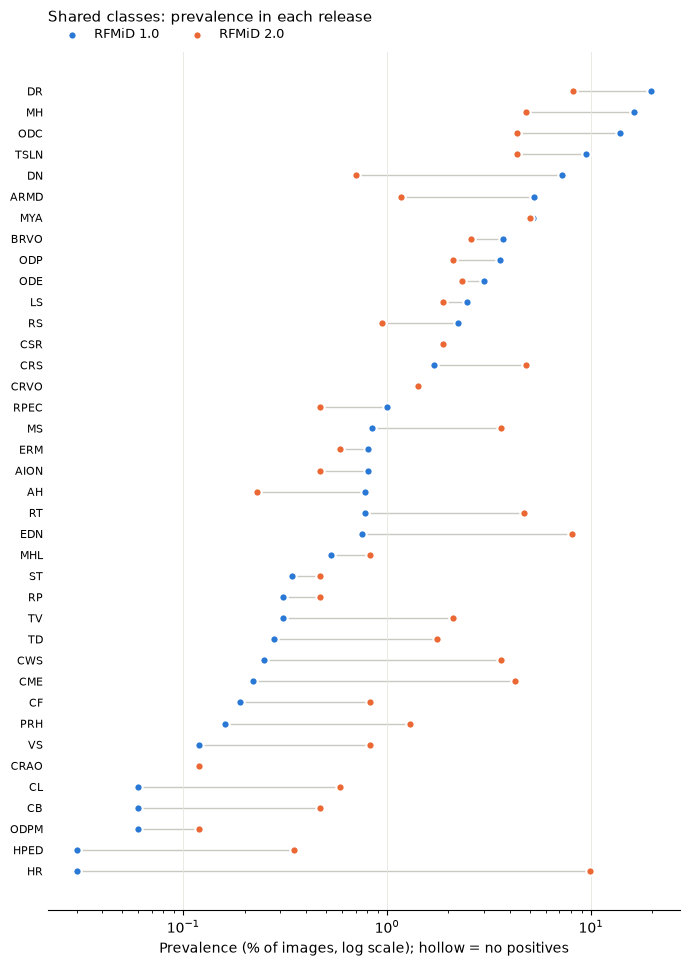

In [ ]:
# Dot plot: one row per shared class, one dot per release, log scale.
# A class with no positives cannot sit on a log axis: it is drawn hollow at the left edge.
BLUE, ORANGE = "#2a78d6", "#eb6834"      # categorical slots 1 and 2
d = shared_prev.sort_values("RFMiD1.0_%")
vals = d[["RFMiD1.0_%", "RFMiD2.0_%"]]
floor = vals[vals > 0].min().min() / 2
y = list(range(len(d)))

fig, ax = plt.subplots(figsize=(7, 0.22 * len(d) + 1.4))
ax.hlines(y, vals.clip(lower=floor).min(axis=1), vals.clip(lower=floor).max(axis=1),
          color="#c9c8c1", lw=1, zorder=1)
for col, color, label in (("RFMiD1.0_%", BLUE, "RFMiD 1.0"), ("RFMiD2.0_%", ORANGE, "RFMiD 2.0")):
    pos, zero = d[col] > 0, d[col] == 0
    ax.scatter(d.loc[pos, col], [i for i, p in zip(y, pos) if p], s=36, color=color, label=label,
               edgecolor="white", linewidth=1.5, zorder=3)
    ax.scatter([floor] * zero.sum(), [i for i, z in zip(y, zero) if z], s=36, facecolor="white",
               edgecolor=color, linewidth=1.5, zorder=3)
ax.set_xscale("log")
ax.set_yticks(y, d.index, fontsize=8)
ax.set_xlabel("Prevalence (% of images, log scale); hollow = no positives")
ax.set_title("Shared classes: prevalence in each release", loc="left", fontsize=11, pad=22)
ax.legend(frameon=False, fontsize=9, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.grid(axis="x", color="#e6e5df", lw=0.6)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(config.FIGURE_DIR / "shared_class_prevalence.png", dpi=200)
plt.show()

In [8]:
SAMPLE_PER_SPLIT = 50

size_rows = []
for man in (man1, man2):
    for split, m in man.items():
        sub = m if SAMPLE_PER_SPLIT is None else m.sample(min(SAMPLE_PER_SPLIT, len(m)), random_state=0)
        for p in sub["path"]:
            w, h = data.image_size(p)
            size_rows.append({"dataset": m["dataset"].iat[0], "split": split, "size": f"{w}x{h}"})
sizes = pd.DataFrame(size_rows)
display(sizes.groupby(["dataset", "size"]).size().rename("images").reset_index())

,dataset,size,images
0,RFMiD1.0,2048x1536,12
1,RFMiD1.0,2144x1424,104
2,RFMiD1.0,4288x2848,34
3,RFMiD2.0,1504x1000,18
4,RFMiD2.0,2048x1536,45
5,RFMiD2.0,512x512,87


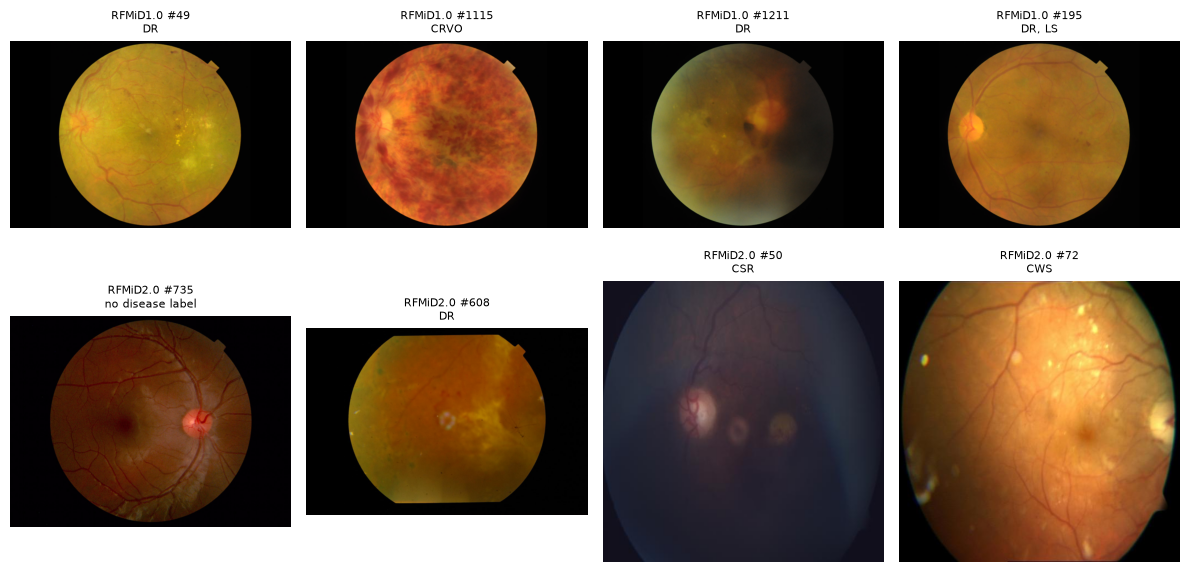

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row, (man, classes) in enumerate(((man1, classes1), (man2, classes2))):
    sample = man["train"].sample(4, random_state=1)
    for ax, (_, r) in zip(axes[row], sample.iterrows()):
        with Image.open(r["path"]) as im:
            im.thumbnail((512, 512))
            ax.imshow(im)
        pos = [c for c in classes if r[c] == 1]
        ax.set_title(f"{r['dataset']} #{r['ID']}\n{', '.join(pos[:3]) or 'no disease label'}", fontsize=8)
        ax.axis("off")
fig.tight_layout()
plt.show()

In [10]:
for key, man in (("rfmid1", man1), ("rfmid2", man2)):
    for split, m in man.items():
        m.to_csv(config.MANIFEST_DIR / f"{key}_{split}.csv", index=False)

with open(config.MANIFEST_DIR / "label_space.json", "w") as f:
    json.dump({"rfmid1_classes": classes1, "rfmid2_classes": classes2, **space}, f, indent=2)

reports.to_json(config.MANIFEST_DIR / "integrity_report.json", orient="records", indent=2)
shared_prev.to_csv(config.MANIFEST_DIR / "shared_class_prevalence.csv")

for p in sorted(config.MANIFEST_DIR.iterdir()):
    print(p.relative_to(config.PROJECT_ROOT))

outputs\manifests\.gitkeep
outputs\manifests\integrity_report.json
outputs\manifests\label_space.json
outputs\manifests\rfmid1_test.csv
outputs\manifests\rfmid1_train.csv
outputs\manifests\rfmid1_val.csv
outputs\manifests\rfmid2_test.csv
outputs\manifests\rfmid2_train.csv
outputs\manifests\rfmid2_val.csv
outputs\manifests\shared_class_prevalence.csv


In [12]:
m2 = pd.concat(man2.values(), ignore_index=True)
print(pd.crosstab(m2["HR"], m2["HTN"]))

HTN    0   1
HR          
0    759  11
1     84   0
